# Adversarial Padding trên dữ liệu flow-based Distrinet-CIC-IDS2017

## Phạm vi và giả định

- Chỉ áp dụng Padding lên Attack flows (`Label_binary == 1`); Benign flows giữ nguyên.
- Padding được biểu diễn bằng mức tăng tổng byte chiều Fwd (`Fwd Packets Length Total`).
- `Fwd Act Data Packets` được dùng làm số lượng đơn vị Padding ở mức flow.
- Các feature có thể tính lại trực tiếp từ tổng byte và số packet sẽ được cập nhật bằng công thức.
- Các thống kê phân phối packet như Min/Max/Std và các thống kê Subflow/Bulk không được tái tạo vì CSV flow không chứa phân phối packet gốc. Chúng được giữ nguyên và ghi rõ là không được tái ước lượng.
- Không sử dụng MTU như một ràng buộc packet-level. Mức Padding được giới hạn để các quan hệ flow-level được kiểm tra không bị phá vỡ.
- Không loại dòng khỏi test set. Flow không áp dụng được hoặc biến đổi không hợp lệ sẽ giữ nguyên và được đánh dấu.

**Diễn giải kết quả:** đây là mô phỏng biến đổi trong không gian đặc trưng flow-based, không phải bằng chứng rằng các feature sau biến đổi có thể được tái tạo chính xác từ PCAP/packet thực tế.


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [ ]:
# ================= THAM SO =================
TEST_PATH   = None
PAD_LEVELS  = [16, 64, 256]       # byte cộng thêm trên mỗi đơn vị Fwd Act Data Packet
PAD_MODES   = ["static", "random"]
SEED        = 42
SAVE_SCALED = True
OUT_SUBDIR  = "perturbed_test_flow_level"


In [ ]:
# ================= THAM SO =================

# Thu muc chua output cua notebook 00
INPUT_DIR = (
    "/content/drive/MyDrive/NTTU/HK1-2027/TTTN/"
    "[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/"
    "04_Quality_Assurance_QC/tạo biến đổi feature/"
    "baseline (70_15_15)/31_10/artifacts"
)

# Thu muc luu output cua notebook Padding
OUTPUT_DIR = (
    "/content/drive/MyDrive/NTTU/HK1-2027/TTTN/"
    "[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/"
    "04_Quality_Assurance_QC/tạo biến đổi feature/"
    "baseline (70_15_15)/1_11/perturbed_test"
)

In [ ]:
import os, glob, json, sys, joblib, warnings, zlib
import numpy as np
import pandas as pd
warnings.filterwarnings("ignore")

# ================= INPUT / OUTPUT PATH =================

CONFIG_PATH = os.path.join(INPUT_DIR, "config.json")
RAW_TEST_PATH = os.path.join(INPUT_DIR, "test_raw.parquet")
SCALER_PATH = os.path.join(INPUT_DIR, "scaler.joblib")

# Kiem tra file dau vao
assert os.path.isfile(CONFIG_PATH), (
    f"Khong tim thay config.json: {CONFIG_PATH}"
)

assert os.path.isfile(RAW_TEST_PATH) or TEST_PATH is not None, (
    f"Khong tim thay test_raw.parquet: {RAW_TEST_PATH}"
)

# Doc config
with open(CONFIG_PATH, "r", encoding="utf-8") as f:
    cfg = json.load(f)

# Lay feature list tu config cua notebook 00
FEATURES = cfg["features"]

# ART duoc dung o cac cell sau de tim input artifact
ART = INPUT_DIR

# Khong su dung out_dir cu trong config.json nua
OUT = OUTPUT_DIR
os.makedirs(OUT, exist_ok=True)

# Kiem tra dung loai perturbation
assert cfg.get(
    "perturbation", "adversarial_padding_only"
) == "adversarial_padding_only"

print("Input directory :", INPUT_DIR)
print("Config          :", CONFIG_PATH)
print("Test data       :", TEST_PATH or RAW_TEST_PATH)
print("Scaler          :", SCALER_PATH if os.path.isfile(SCALER_PATH) else "Khong co")
print("Output directory:", OUT)
print("Feature scope   :", cfg.get("feature_scope", "flow_level_feature_space_padding"))
print("So feature      :", len(FEATURES))


Input directory : /content/drive/MyDrive/NTTU/HK1-2027/TTTN/[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/04_Quality_Assurance_QC/tạo biến đổi feature/baseline (70_15_15)/31_10/artifacts
Config          : /content/drive/MyDrive/NTTU/HK1-2027/TTTN/[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/04_Quality_Assurance_QC/tạo biến đổi feature/baseline (70_15_15)/31_10/artifacts/config.json
Test data       : /content/drive/MyDrive/NTTU/HK1-2027/TTTN/[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/04_Quality_Assurance_QC/tạo biến đổi feature/baseline (70_15_15)/31_10/artifacts/test_raw.parquet
Scaler          : /content/drive/MyDrive/NTTU/HK1-2027/TTTN/[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/04_Quality_Assurance_QC/tạo biến đổi feature/baseline (70_15_15)/31_10/artifacts/scaler.joblib
Output directory: /content/drive/MyDrive/NTTU/HK1-2027/TTTN/[DTG_TTTN]_NIDS_Adversarial_Robustness_Team/04_Quality_Assurance_QC/tạo biến đổi feature/baseline (70_15_15)/1_11/perturbed_test
Fea

## 1. Tạo thư viện biến đổi và Validator

Hai thư viện dưới đây được ghi thành file Python để dễ kiểm thử và tái sử dụng.


In [ ]:
%%writefile perturb_lib.py
"""Feature-level Adversarial Padding for flow-based tabular data.

This module deliberately does NOT claim packet-level reconstruction.
Only aggregate features derivable from flow totals/counts are recalculated.
Packet-distribution, subflow and bulk statistics are preserved because their
underlying packet-level sufficient statistics are not available in the flow row.
"""
import numpy as np
import pandas as pd

# Directly modified feature.
MUTABLE_COLS = ["Fwd Packets Length Total"]

# Recomputed from flow totals/counts with explicit algebraic definitions.
DERIVED_COLS = [
    "Fwd Packet Length Mean",
    "Packet Length Mean",
    "Avg Packet Size",
    "Avg Fwd Segment Size",
    "Flow Bytes/s",
]

# All columns the engine may change.
MODIFIABLE_COLS = MUTABLE_COLS + DERIVED_COLS

# Features intentionally preserved: their exact updated values cannot be
# recovered from aggregate flow features alone.
PRESERVED_UNIDENTIFIABLE_COLS = [
    "Fwd Packet Length Min", "Fwd Packet Length Max", "Fwd Packet Length Std",
    "Packet Length Min", "Packet Length Max", "Packet Length Std",
    "Packet Length Variance", "Subflow Fwd Bytes",
    "Fwd Avg Bytes/Bulk", "Fwd Avg Bulk Rate",
]

def _arr(df, col):
    return pd.to_numeric(df[col], errors="coerce").to_numpy(dtype=np.float64)

def apply_padding(df, pad_bytes, mode="static", rng=None):
    """Return (perturbed_df, applicable_mask, bytes_added).

    static: pad every Fwd Act Data Packet represented by the flow.
    random: select each Fwd Act Data Packet independently with p=0.5.

    `pad_bytes` is a flow-feature-space increment per selected data packet.
    The maximum increment is constrained so updated Fwd/overall means do not
    exceed the corresponding preserved Max features, when those columns exist.
    """
    if mode not in ("static", "random"):
        raise ValueError("mode must be 'static' or 'random'")
    if not np.isfinite(pad_bytes) or pad_bytes <= 0:
        raise ValueError("pad_bytes must be a positive finite number")
    rng = rng if rng is not None else np.random.default_rng(0)
    out = df.copy()
    n_rows = len(df)

    required = [
        "Fwd Act Data Packets", "Total Fwd Packets", "Total Backward Packets",
        "Fwd Packets Length Total", "Bwd Packets Length Total",
        "Flow Duration", "Fwd Packet Length Mean", "Packet Length Mean",
        "Avg Packet Size", "Avg Fwd Segment Size", "Flow Bytes/s",
    ]
    missing = [c for c in required if c not in df.columns]
    if missing:
        raise KeyError(f"Missing required flow features: {missing}")

    active = np.clip(_arr(df, "Fwd Act Data Packets"), 0, None)
    fwd_n = np.clip(_arr(df, "Total Fwd Packets"), 0, None)
    bwd_n = np.clip(_arr(df, "Total Backward Packets"), 0, None)
    total_n = fwd_n + bwd_n
    fwd_total = _arr(df, "Fwd Packets Length Total")
    bwd_total = _arr(df, "Bwd Packets Length Total")
    fwd_mean = _arr(df, "Fwd Packet Length Mean")
    all_mean = _arr(df, "Packet Length Mean")
    fwd_max = _arr(df, "Fwd Packet Length Max") if "Fwd Packet Length Max" in df else np.full(n_rows, np.inf)
    all_max = _arr(df, "Packet Length Max") if "Packet Length Max" in df else np.full(n_rows, np.inf)
    duration = _arr(df, "Flow Duration")

    if mode == "static":
        selected = np.floor(active)
    else:
        selected = rng.binomial(np.floor(active).astype(np.int64), 0.5).astype(np.float64)

    # Flow-level budget. Do not infer per-packet lengths; cap total byte change
    # so the recomputed means do not exceed preserved maxima.
    requested_add = selected * float(pad_bytes)
    max_add_fwd = np.maximum(0.0, (fwd_max - fwd_mean) * np.maximum(fwd_n, 0))
    max_add_all = np.maximum(0.0, (all_max - all_mean) * np.maximum(total_n, 0))
    max_add = np.minimum(max_add_fwd, max_add_all)
    add = np.minimum(requested_add, max_add)
    add = np.where((active >= 1) & (fwd_n > 0) & (total_n > 0), add, 0.0)

    applicable = add > 0
    new_fwd_total = fwd_total + add
    new_total_bytes = new_fwd_total + bwd_total

    def assign_if_present(col, values):
        if col in out.columns:
            out[col] = np.where(applicable, values, _arr(df, col))

    # The only directly mutable quantity.
    assign_if_present("Fwd Packets Length Total", new_fwd_total)

    # Exact aggregate recomputation under the feature definitions:
    # mean = total bytes / packet count; packet count and duration are fixed.
    new_fwd_mean = np.divide(new_fwd_total, fwd_n, out=fwd_mean.copy(), where=fwd_n > 0)
    new_all_mean = np.divide(new_total_bytes, total_n, out=all_mean.copy(), where=total_n > 0)
    assign_if_present("Fwd Packet Length Mean", new_fwd_mean)
    assign_if_present("Avg Fwd Segment Size", new_fwd_mean)
    assign_if_present("Packet Length Mean", new_all_mean)
    assign_if_present("Avg Packet Size", new_all_mean)

    # Flow Bytes/s is recomputed from total flow bytes / duration in seconds.
    old_rate = _arr(df, "Flow Bytes/s")
    new_rate = np.divide(
        new_total_bytes, duration / 1e6,
        out=old_rate.copy(), where=duration > 0
    )
    assign_if_present("Flow Bytes/s", new_rate)

    # Keep all other packet-distribution/subflow/bulk features unchanged.
    return out, applicable, add


Overwriting perturb_lib.py


In [ ]:
%%writefile validator_lib.py
"""Flow-level validator for feature-space Adversarial Padding."""
import numpy as np
import pandas as pd
from perturb_lib import MODIFIABLE_COLS

def _tol(x):
    return 1e-6 * np.abs(x) + 1e-9

def validate(original, perturbed):
    """Return per-rule Boolean violations (True means newly invalid)."""
    if list(original.columns) != list(perturbed.columns):
        raise ValueError("Original and perturbed columns/order must match")
    if len(original) != len(perturbed):
        raise ValueError("Original and perturbed must have equal row counts")

    cols = list(original.columns)
    O = original.to_numpy(dtype=np.float64)
    P = perturbed.to_numpy(dtype=np.float64)
    result = {}

    orig_finite = np.isfinite(O).all(axis=1)
    pert_finite = np.isfinite(P).all(axis=1)
    result["non_finite_new"] = (~pert_finite) & orig_finite

    mutable = [c for c in MODIFIABLE_COLS if c in cols]
    immutable = [c for c in cols if c not in MODIFIABLE_COLS]
    if mutable:
        Om = original[mutable].to_numpy(dtype=np.float64)
        Pm = perturbed[mutable].to_numpy(dtype=np.float64)
        result["negative_value_new"] = ((Pm < 0) & (Om >= 0)).any(axis=1)
        result["modifiable_decreased"] = (Pm < Om - _tol(Om)).any(axis=1)
    else:
        result["negative_value_new"] = np.zeros(len(original), dtype=bool)
        result["modifiable_decreased"] = np.zeros(len(original), dtype=bool)

    if immutable:
        Oi = original[immutable].to_numpy(dtype=np.float64)
        Pi = perturbed[immutable].to_numpy(dtype=np.float64)
        result["immutable_changed"] = (np.abs(Pi - Oi) > _tol(Oi)).any(axis=1)
    else:
        result["immutable_changed"] = np.zeros(len(original), dtype=bool)

    # Check only relationships relevant to updated aggregate means.
    order_checks = [
        ("Fwd Packet Length Min", "Fwd Packet Length Mean", "Fwd Packet Length Max"),
        ("Packet Length Min", "Packet Length Mean", "Packet Length Max"),
    ]
    order_bad = np.zeros(len(original), dtype=bool)
    for lo, mid, hi in order_checks:
        if all(c in cols for c in (lo, mid, hi)):
            def violates(frame):
                l = frame[lo].to_numpy(float)
                m = frame[mid].to_numpy(float)
                h = frame[hi].to_numpy(float)
                return (l > m + _tol(m)) | (m > h + _tol(h))
            order_bad |= violates(perturbed) & ~violates(original)
    result["min_mean_max_new"] = order_bad

    total_bad = np.zeros(len(original), dtype=bool)
    pairs = [
        ("Fwd Packet Length Max", "Fwd Packets Length Total"),
        ("Fwd Packet Length Mean", "Fwd Packets Length Total"),
    ]
    for small, big in pairs:
        if small in cols and big in cols:
            def violates(frame):
                s = frame[small].to_numpy(float)
                b = frame[big].to_numpy(float)
                return s > b + _tol(b)
            total_bad |= violates(perturbed) & ~violates(original)
    result["fwd_total_consistency_new"] = total_bad

    # Verify exact aggregate equations implemented by this engine.
    eq_bad = np.zeros(len(original), dtype=bool)
    required = ["Fwd Packets Length Total", "Fwd Packet Length Mean",
                "Total Fwd Packets", "Avg Fwd Segment Size",
                "Bwd Packets Length Total", "Total Backward Packets",
                "Packet Length Mean", "Avg Packet Size"]
    if all(c in cols for c in required):
        def equation_bad(frame):
            ft = frame["Fwd Packets Length Total"].to_numpy(float)
            fn = frame["Total Fwd Packets"].to_numpy(float)
            fm = frame["Fwd Packet Length Mean"].to_numpy(float)
            seg = frame["Avg Fwd Segment Size"].to_numpy(float)
            bt = frame["Bwd Packets Length Total"].to_numpy(float)
            bn = frame["Total Backward Packets"].to_numpy(float)
            pm = frame["Packet Length Mean"].to_numpy(float)
            ap = frame["Avg Packet Size"].to_numpy(float)
            tn = fn + bn
            expected_fm = np.divide(ft, fn, out=fm.copy(), where=fn > 0)
            expected_pm = np.divide(ft + bt, tn, out=pm.copy(), where=tn > 0)
            bad = (np.abs(fm - expected_fm) > 1e-5 * np.maximum(1, np.abs(expected_fm)))
            bad |= (np.abs(seg - fm) > 1e-5 * np.maximum(1, np.abs(fm)))
            bad |= (np.abs(pm - expected_pm) > 1e-5 * np.maximum(1, np.abs(expected_pm)))
            bad |= (np.abs(ap - pm) > 1e-5 * np.maximum(1, np.abs(pm)))
            return bad
        eq_bad = equation_bad(perturbed) & ~equation_bad(original)
    result["aggregate_equations_new"] = eq_bad

    return pd.DataFrame(result, index=original.index)

def violation_report(violations):
    n = len(violations)
    rows = [{"rule": c, "n_violations": int(violations[c].sum()),
             "pct_of_rows": round(100 * float(violations[c].mean()), 3) if n else 0.0}
            for c in violations.columns]
    any_bad = violations.any(axis=1) if len(violations.columns) else np.zeros(n, dtype=bool)
    rows.append({"rule": "ANY", "n_violations": int(np.sum(any_bad)),
                 "pct_of_rows": round(100 * float(np.mean(any_bad)), 3) if n else 0.0})
    return pd.DataFrame(rows)


Overwriting validator_lib.py


In [ ]:
import importlib
import perturb_lib as PL
import validator_lib as VL
importlib.reload(PL)
importlib.reload(VL)

def run_padding(test, features, pad_bytes, mode, seed, tag):
    """Transform attack rows; retain every input row in original order."""
    rng = np.random.default_rng(seed + zlib.crc32(tag.encode("utf-8")))
    attack_mask = test["Label_binary"].to_numpy(dtype=int) == 1
    attack_pos = np.flatnonzero(attack_mask)
    X_attack = test.iloc[attack_pos][features].reset_index(drop=True)

    pert, applicable, added = PL.apply_padding(X_attack, pad_bytes, mode, rng)
    violations = VL.validate(X_attack, pert)
    invalid = violations.any(axis=1).to_numpy()
    applied = applicable & ~invalid

    # Revert any failed transformation to the original row; never drop rows.
    values = test[features].to_numpy(dtype=np.float64, copy=True)
    pert_values = pert.to_numpy(dtype=np.float64)
    values[attack_pos[applied]] = pert_values[applied]

    out = pd.DataFrame(values, columns=features)
    out["Label"] = test["Label"].astype(str).to_numpy()
    out["Label_binary"] = test["Label_binary"].astype(int).to_numpy()
    out["__orig_row"] = np.arange(len(test), dtype=np.int64)

    applicable_full = np.zeros(len(test), dtype=bool)
    applied_full = np.zeros(len(test), dtype=bool)
    invalid_full = np.zeros(len(test), dtype=bool)
    added_full = np.zeros(len(test), dtype=np.float64)
    applicable_full[attack_pos] = applicable
    applied_full[attack_pos] = applied
    invalid_full[attack_pos] = invalid
    added_full[attack_pos] = np.where(applied, added, 0.0)

    out["__padding_applicable"] = applicable_full
    out["__padding_applied"] = applied_full
    out["__validation_failed"] = invalid_full
    out["__fwd_bytes_added"] = added_full

    summary = {
        "tag": tag, "mode": mode, "pad_bytes_per_active_packet": pad_bytes,
        "n_test": len(test), "n_output": len(out),
        "n_benign": int((~attack_mask).sum()), "n_attack": int(attack_mask.sum()),
        "n_attack_applicable": int(applicable.sum()),
        "n_attack_applied": int(applied.sum()),
        "n_attack_not_applicable": int((~applicable).sum()),
        "n_attack_validation_failed": int(invalid.sum()),
        "n_rows_dropped": 0,
    }
    return out, summary, violations


## 2. Nạp tập test thô


In [ ]:
path = TEST_PATH or os.path.join(ART, "test_raw.parquet")
test = pd.read_parquet(path) if path.endswith(".parquet") else pd.read_csv(path)
test["Label"] = test["Label"].astype(str)

missing = [c for c in FEATURES + ["Label", "Label_binary"] if c not in test.columns]
assert not missing, f"Thiếu cột: {missing}"
assert test["Label_binary"].isin([0, 1]).all(), "Label_binary phải chỉ gồm 0/1"
assert np.isfinite(test[FEATURES].to_numpy(dtype=np.float64)).all(), "Input có NaN/Inf"
print("Test:", test.shape,
      "| attack:", int((test.Label_binary == 1).sum()),
      "| benign:", int((test.Label_binary == 0).sum()))
display(test.loc[test.Label_binary == 1, "Label"].value_counts().rename("n_attack").to_frame())


Test: (260632, 85) | attack: 42169 | benign: 218463


,n_attack
Label,
DoS Hulk,23756
DDoS,14222
DoS GoldenEye,1163
Infiltration - Portscan,709
FTP-Patator,602
DoS Slowloris,590
SSH-Patator,476
DoS Slowhttptest,260
Portscan,245


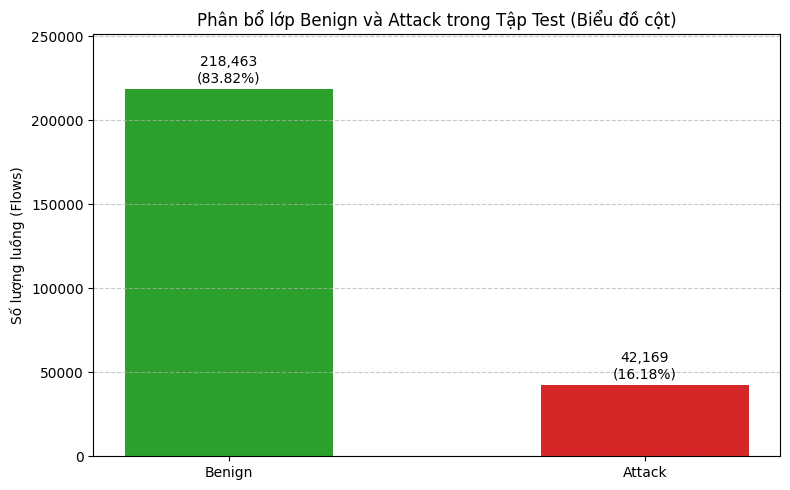

In [ ]:
import matplotlib.pyplot as plt

# Thống kê số lượng dòng theo nhãn
counts = test["Label_binary"].value_counts()
labels = ["Benign" if idx == 0 else "Attack" for idx in counts.index]

# Vẽ biểu đồ cột
fig, ax = plt.subplots(figsize=(8, 5))
bars = ax.bar(labels, counts, color=["#2ca02c", "#d62728"], width=0.5)

# Thêm nhãn số lượng và tỷ lệ phần trăm trên đầu mỗi cột
total = counts.sum()
for bar in bars:
    height = bar.get_height()
    percentage = (height / total) * 100
    ax.annotate(f'{height:,}\n({percentage:.2f}%)',
                xy=(bar.get_x() + bar.get_width() / 2, height),
                xytext=(0, 3),  # offset 3 points vertically
                textcoords="offset points",
                ha='center', va='bottom', fontsize=10)

ax.set_title("Phân bổ lớp Benign và Attack trong Tập Test (Biểu đồ cột)")
ax.set_ylabel("Số lượng luồng (Flows)")
ax.set_ylim(0, max(counts) * 1.15)  # Tạo khoảng trống phía trên để hiển thị label
ax.grid(axis='y', linestyle='--', alpha=0.7)

plt.tight_layout()
plt.show()

## 3. Chạy các kịch bản Padding


In [ ]:
scaler = None
if SAVE_SCALED:
    scaler_path = os.path.join(ART, "scaler.joblib")
    if os.path.exists(scaler_path):
        scaler = joblib.load(scaler_path)
    else:
        print("Không tìm thấy scaler.joblib; chỉ lưu dữ liệu chưa scale.")

summaries, kept, violation_logs = [], {}, []
for mode in PAD_MODES:
    for pad_level in PAD_LEVELS:
        tag = f"padding_{mode}_{pad_level}B"
        out, summary, violations = run_padding(
            test, FEATURES, pad_level, mode, SEED, tag
        )

        assert len(out) == len(test), "Lỗi: số dòng đầu ra phải bằng số dòng đầu vào."
        assert np.array_equal(out["__orig_row"].to_numpy(), np.arange(len(test)))

        out_path = os.path.join(OUT, f"test_{tag}.parquet")
        out.to_parquet(out_path, index=False)

        if scaler is not None:
            X_scaled = scaler.transform(out[FEATURES].to_numpy(dtype=np.float64)).astype(np.float32)
            np.savez_compressed(
                os.path.join(OUT, f"test_{tag}_scaled.npz"),
                X_test=X_scaled,
                y_test=out["Label_binary"].to_numpy(dtype=int),
                labels=out["Label"].to_numpy(dtype=str),
                padding_applicable=out["__padding_applicable"].to_numpy(dtype=bool),
                padding_applied=out["__padding_applied"].to_numpy(dtype=bool),
                validation_failed=out["__validation_failed"].to_numpy(dtype=bool),
                orig_row=out["__orig_row"].to_numpy(dtype=np.int64),
                feature_names=np.array(FEATURES),
            )

        report = VL.violation_report(violations)
        summary.update({f"viol_{r.rule}": int(r.n_violations)
                        for r in report.itertuples(index=False)})
        summaries.append(summary)
        kept[tag] = out
        violation_logs.append((tag, report))

        print(
            f"{tag}: applied {summary['n_attack_applied']}/{summary['n_attack']} "
            f"| not applicable {summary['n_attack_not_applicable']} "
            f"| validation failed {summary['n_attack_validation_failed']} "
            f"| rows {len(out)}"
        )

summary_df = pd.DataFrame(summaries)
summary_df.to_csv(os.path.join(OUT, "padding_summary.csv"), index=False)
pd.concat(
    [r.assign(tag=tag) for tag, r in violation_logs],
    ignore_index=True
).to_csv(os.path.join(OUT, "validation_report.csv"), index=False)

manifest = {
    "input": path,
    "feature_scope": "flow_level_feature_space_padding",
    "perturbation": "adversarial_padding_only",
    "pad_levels": PAD_LEVELS,
    "modes": PAD_MODES,
    "seed": SEED,
    "features": FEATURES,
    "mutable_features": PL.MUTABLE_COLS,
    "derived_features_recomputed": PL.DERIVED_COLS,
    "distribution_features_preserved_due_to_missing_packet_statistics": PL.PRESERVED_UNIDENTIFIABLE_COLS,
    "packet_level_claim": False,
    "rows_dropped": 0,
}
with open(os.path.join(OUT, "manifest.json"), "w", encoding="utf-8") as f:
    json.dump(manifest, f, ensure_ascii=False, indent=2)

display(summary_df)


padding_static_16B: applied 40991/42169 | not applicable 1178 | validation failed 0 | rows 260632
padding_static_64B: applied 40991/42169 | not applicable 1178 | validation failed 0 | rows 260632
padding_static_256B: applied 40991/42169 | not applicable 1178 | validation failed 0 | rows 260632
padding_random_16B: applied 22227/42169 | not applicable 19942 | validation failed 0 | rows 260632
padding_random_64B: applied 22259/42169 | not applicable 19910 | validation failed 0 | rows 260632
padding_random_256B: applied 22053/42169 | not applicable 20116 | validation failed 0 | rows 260632


,tag,mode,pad_bytes_per_active_packet,n_test,n_output,n_benign,n_attack,n_attack_applicable,n_attack_applied,n_attack_not_applicable,n_attack_validation_failed,n_rows_dropped,viol_non_finite_new,viol_negative_value_new,viol_modifiable_decreased,viol_immutable_changed,viol_min_mean_max_new,viol_fwd_total_consistency_new,viol_aggregate_equations_new,viol_ANY
0,padding_static_16B,static,16,260632,260632,218463,42169,40991,40991,1178,0,0,0,0,0,0,0,0,0,0
1,padding_static_64B,static,64,260632,260632,218463,42169,40991,40991,1178,0,0,0,0,0,0,0,0,0,0
2,padding_static_256B,static,256,260632,260632,218463,42169,40991,40991,1178,0,0,0,0,0,0,0,0,0,0
3,padding_random_16B,random,16,260632,260632,218463,42169,22227,22227,19942,0,0,0,0,0,0,0,0,0,0
4,padding_random_64B,random,64,260632,260632,218463,42169,22259,22259,19910,0,0,0,0,0,0,0,0,0,0
5,padding_random_256B,random,256,260632,260632,218463,42169,22053,22053,20116,0,0,0,0,0,0,0,0,0,0


In [ ]:
# Hình biểu diễn Có bao nhiêu kịch bản Padding được thực hiện?
# 3.1. PADDING EXPERIMENT CONFIGURATION

scenario_config = pd.DataFrame([
    {
        "scenario": f"padding_{mode}_{level}B",
        "padding_mode": mode,
        "padding_level_bytes": level,
        "random_selection_probability": 0.5 if mode == "random" else 1.0,
        "seed": SEED
    }
    for mode in PAD_MODES
    for level in PAD_LEVELS
])

display(scenario_config)

scenario_config.to_csv(
    os.path.join(OUT, "padding_scenario_config.csv"),
    index=False
)

,scenario,padding_mode,padding_level_bytes,random_selection_probability,seed
0,padding_static_16B,static,16,1.0,42
1,padding_static_64B,static,64,1.0,42
2,padding_static_256B,static,256,1.0,42
3,padding_random_16B,random,16,0.5,42
4,padding_random_64B,random,64,0.5,42
5,padding_random_256B,random,256,0.5,42


In [ ]:
# 3.2. PADDING EXPERIMENT RESULTS

experiment_rows = []

for tag, out in kept.items():

    attack_mask = out["Label_binary"].to_numpy() == 1
    applied_mask = out["__padding_applied"].to_numpy(dtype=bool)

    attack_count = int(attack_mask.sum())
    applied_count = int(applied_mask.sum())

    added = out.loc[
        applied_mask, "__fwd_bytes_added"
    ].to_numpy(dtype=float)

    experiment_rows.append({
        "scenario": tag,
        "mode": tag.split("_")[1],
        "padding_level": int(tag.split("_")[2].replace("B", "")),

        "total_test_flows": len(out),
        "total_attack_flows": attack_count,
        "applied_flows": applied_count,

        "applied_rate_pct": (
            applied_count / attack_count * 100
            if attack_count else 0
        ),

        "total_bytes_added": float(added.sum()) if len(added) else 0,
        "mean_bytes_added": float(added.mean()) if len(added) else 0,
        "median_bytes_added": float(np.median(added)) if len(added) else 0,
        "max_bytes_added": float(added.max()) if len(added) else 0
    })

experiment_df = pd.DataFrame(experiment_rows)

display(
    experiment_df.round(3)
)

experiment_df.to_csv(
    os.path.join(OUT, "padding_experiment_results.csv"),
    index=False
)

,scenario,mode,padding_level,total_test_flows,total_attack_flows,applied_flows,applied_rate_pct,total_bytes_added,mean_bytes_added,median_bytes_added,max_bytes_added
0,padding_static_16B,static,16,260632,42169,40991,97.206,9.920360e+05,24.201,16.0,1920.0
1,padding_static_64B,static,64,260632,42169,40991,97.206,3.786633e+06,92.377,64.0,7680.0
2,padding_static_256B,static,256,260632,42169,40991,97.206,1.265144e+07,308.639,256.0,30720.0
3,padding_random_16B,random,16,260632,42169,22227,52.709,4.965620e+05,22.340,16.0,928.0
4,padding_random_64B,random,64,260632,42169,22259,52.785,1.940328e+06,87.170,64.0,4032.0
5,padding_random_256B,random,256,260632,42169,22053,52.297,6.465625e+06,293.186,256.0,16896.0


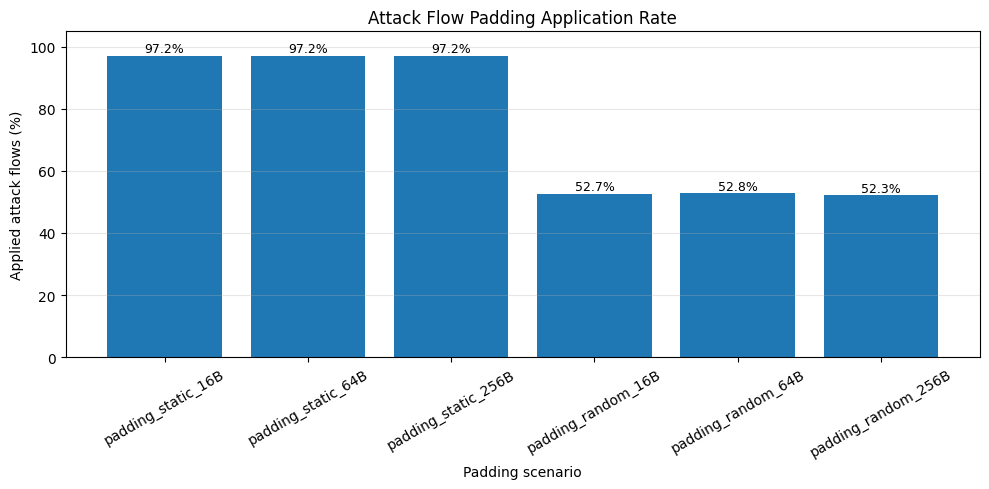

In [ ]:
# 3.3. ATTACK FLOW PADDING RATE

fig, ax = plt.subplots(figsize=(10, 5))

plot_data = experiment_df.copy()

bars = ax.bar(
    plot_data["scenario"],
    plot_data["applied_rate_pct"]
)

ax.set_title("Attack Flow Padding Application Rate")
ax.set_xlabel("Padding scenario")
ax.set_ylabel("Applied attack flows (%)")
ax.set_ylim(0, 105)

ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, plot_data["applied_rate_pct"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height() + 1,
        f"{value:.1f}%",
        ha="center",
        fontsize=9
    )

plt.tight_layout()
plt.show()

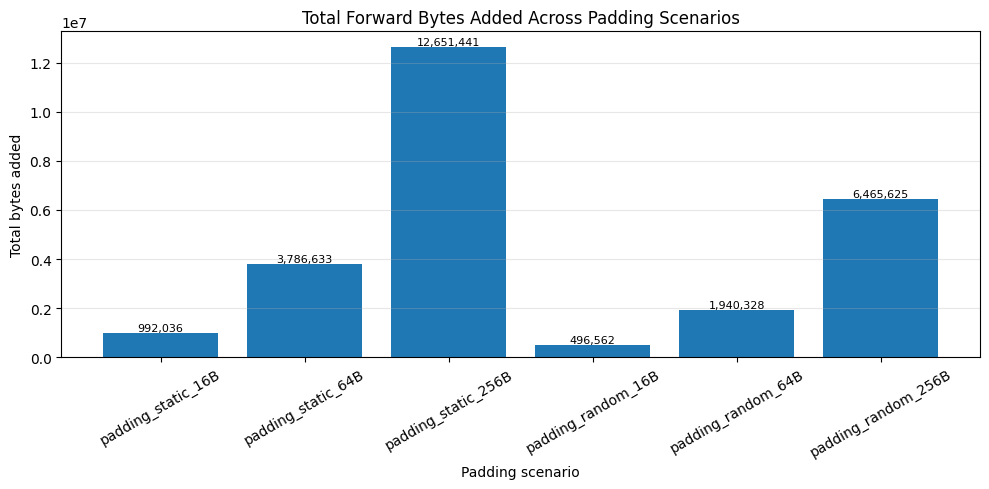

In [ ]:
# 3.4. TOTAL BYTES ADDED BY SCENARIO

fig, ax = plt.subplots(figsize=(10, 5))

plot_data = experiment_df.copy()

bars = ax.bar(
    plot_data["scenario"],
    plot_data["total_bytes_added"]
)

ax.set_title("Total Forward Bytes Added Across Padding Scenarios")
ax.set_xlabel("Padding scenario")
ax.set_ylabel("Total bytes added")

ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)

for bar, value in zip(bars, plot_data["total_bytes_added"]):
    ax.text(
        bar.get_x() + bar.get_width() / 2,
        bar.get_height(),
        f"{value:,.0f}",
        ha="center",
        va="bottom",
        fontsize=8
    )

plt.tight_layout()
plt.show()

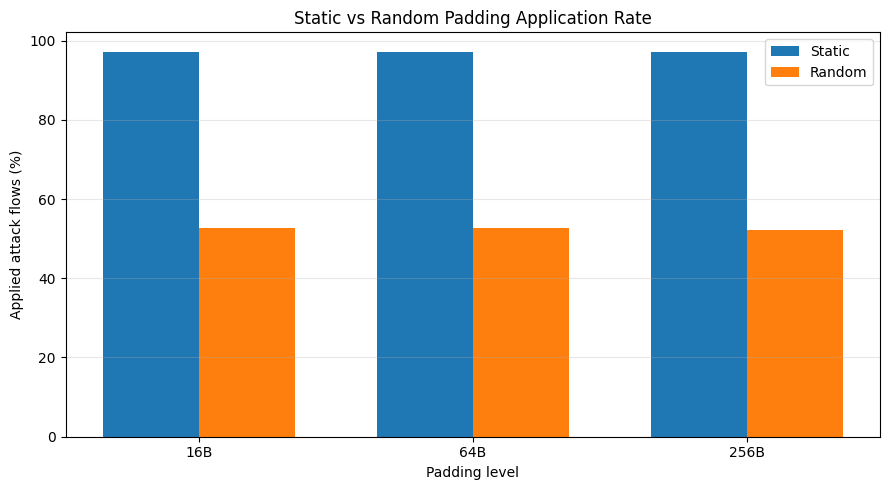

In [ ]:
# 3.5. STATIC VS RANDOM COMPARISON

fig, ax = plt.subplots(figsize=(9, 5))

levels = sorted(experiment_df["padding_level"].unique())

x = np.arange(len(levels))
width = 0.35

for i, mode in enumerate(["static", "random"]):

    subset = (
        experiment_df[experiment_df["mode"] == mode]
        .set_index("padding_level")
        .reindex(levels)
    )

    values = subset["applied_rate_pct"].to_numpy()

    ax.bar(
        x + (i - 0.5) * width,
        values,
        width,
        label=mode.capitalize()
    )

ax.set_xticks(x)
ax.set_xticklabels([f"{v}B" for v in levels])

ax.set_xlabel("Padding level")
ax.set_ylabel("Applied attack flows (%)")
ax.set_title("Static vs Random Padding Application Rate")

ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

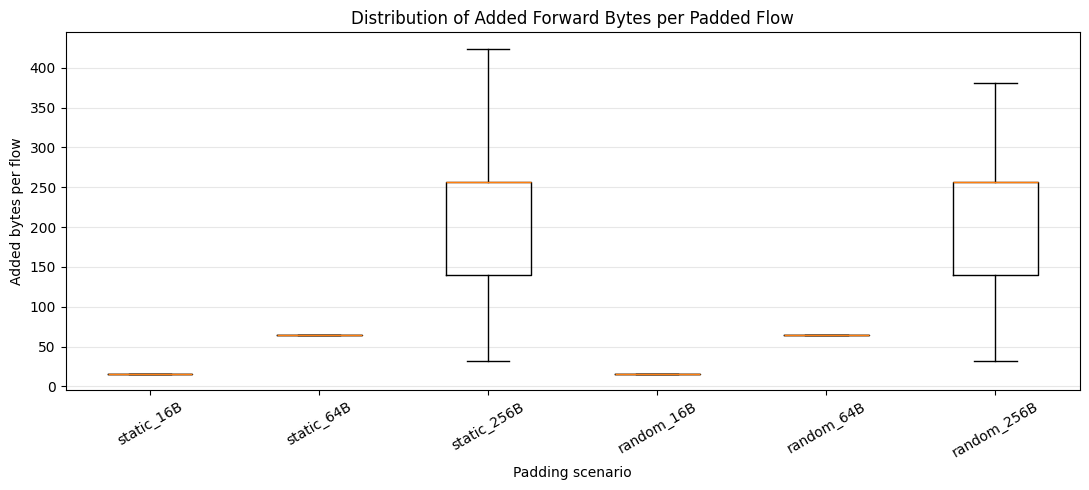

In [ ]:
# 3.6. DISTRIBUTION OF ADDED BYTES PER ATTACK FLOW

box_data = []
box_labels = []

for tag, out in kept.items():

    mask = out["__padding_applied"].to_numpy(dtype=bool)

    added = out.loc[
        mask, "__fwd_bytes_added"
    ].to_numpy(dtype=float)

    if len(added) > 0:
        box_data.append(added)
        box_labels.append(tag.replace("padding_", ""))

fig, ax = plt.subplots(figsize=(11, 5))

ax.boxplot(
    box_data,
    tick_labels=box_labels,
    showfliers=False
)

ax.set_title("Distribution of Added Forward Bytes per Padded Flow")
ax.set_xlabel("Padding scenario")
ax.set_ylabel("Added bytes per flow")

ax.tick_params(axis="x", rotation=30)
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 4. Kiểm tra tính toàn vẹn và chất lượng đầu ra


In [ ]:
# Kiểm tra một kịch bản đại diện (mức Padding lớn nhất, mode đầu tiên)
tag = f"padding_{PAD_MODES[0]}_{PAD_LEVELS[-1]}B"
out = kept[tag]
orig = test.reset_index(drop=True)
assert len(out) == len(orig)

changed = out["__padding_applied"].to_numpy(dtype=bool)
failed = out["__validation_failed"].to_numpy(dtype=bool)
not_applied = ~out["__padding_applicable"].to_numpy(dtype=bool)
benign = out["Label_binary"].to_numpy(dtype=int) == 0

checks = {
    "Giữ nguyên số dòng": len(out) == len(orig),
    "Giữ nguyên thứ tự dòng": np.array_equal(out["__orig_row"], np.arange(len(orig))),
    "Nhãn không thay đổi": np.array_equal(out["Label"].to_numpy(), orig["Label"].to_numpy())
        and np.array_equal(out["Label_binary"].to_numpy(), orig["Label_binary"].to_numpy()),
    "Benign giữ nguyên": np.array_equal(out.loc[benign, FEATURES].to_numpy(),
                                         orig.loc[benign, FEATURES].to_numpy()),
    "Flow không áp dụng Padding giữ nguyên": np.array_equal(
        out.loc[not_applied, FEATURES].to_numpy(), orig.loc[not_applied, FEATURES].to_numpy()
    ),
    "Flow validation failed được hoàn nguyên": np.array_equal(
        out.loc[failed, FEATURES].to_numpy(), orig.loc[failed, FEATURES].to_numpy()
    ),
    "Flow được Padding có byte Fwd tăng": bool(
        (out.loc[changed, "Fwd Packets Length Total"].to_numpy()
         > orig.loc[changed, "Fwd Packets Length Total"].to_numpy()).all()
    ) if changed.any() else True,
    "Không có NaN/Inf đầu ra": bool(np.isfinite(out[FEATURES].to_numpy(dtype=float)).all()),
    "Không có flow bị loại": int(len(out)) == int(len(test)),
}
display(pd.Series(checks, name="passed").to_frame())
assert all(checks.values()), "Một hoặc nhiều kiểm tra chất lượng không đạt."
print("Scenario:", tag)


,passed
Giữ nguyên số dòng,True
Giữ nguyên thứ tự dòng,True
Nhãn không thay đổi,True
Benign giữ nguyên,True
Flow không áp dụng Padding giữ nguyên,True
Flow validation failed được hoàn nguyên,True
Flow được Padding có byte Fwd tăng,True
Không có NaN/Inf đầu ra,True
Không có flow bị loại,True


Scenario: padding_static_256B


Trả lời "Với từng mức Padding, có bao nhiêu Attack flow thực sự được biến đổi thành công?" Dùng hình sau

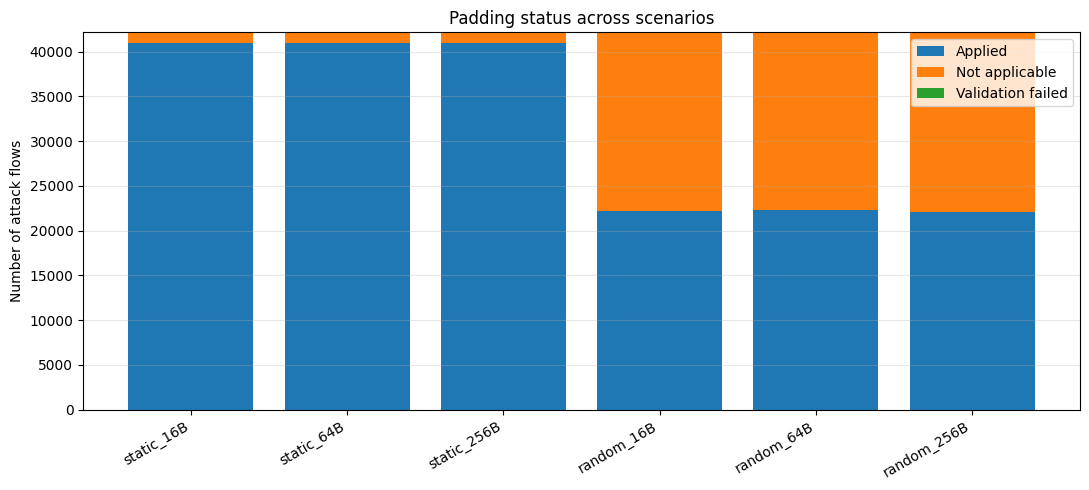

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

plot_df = summary_df.copy()

plot_df["scenario"] = plot_df["mode"] + "_" + plot_df["pad_bytes_per_active_packet"].astype(str) + "B"

x = np.arange(len(plot_df))

fig, ax = plt.subplots(figsize=(11, 5))

applied = plot_df["n_attack_applied"].to_numpy()
not_applicable = plot_df["n_attack_not_applicable"].to_numpy()
failed = plot_df["n_attack_validation_failed"].to_numpy()

ax.bar(x, applied, label="Applied")
ax.bar(x, not_applicable, bottom=applied, label="Not applicable")
ax.bar(x, failed, bottom=applied + not_applicable, label="Validation failed")

ax.set_xticks(x)
ax.set_xticklabels(plot_df["scenario"], rotation=30, ha="right")
ax.set_ylabel("Number of attack flows")
ax.set_title("Padding status across scenarios")
ax.legend()
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

## 5. Phân tích mức thay đổi feature

Các tỷ lệ dưới đây chỉ tính trên flow thực sự được Padding. Những feature được giữ nguyên do thiếu thống kê packet-level không được diễn giải là đã được tái tạo.


In [ ]:
cols_to_report = [
    "Fwd Packets Length Total", "Fwd Packet Length Mean",
    "Packet Length Mean", "Avg Packet Size",
    "Avg Fwd Segment Size", "Flow Bytes/s",
]
ratio_rows = {}
for tag, out in kept.items():
    mask = out["__padding_applied"].to_numpy(dtype=bool)
    if not mask.any():
        ratio_rows[tag] = {c: np.nan for c in cols_to_report}
        continue
    original_rows = orig.iloc[out.loc[mask, "__orig_row"].to_numpy()].reset_index(drop=True)
    changed_rows = out.loc[mask].reset_index(drop=True)
    ratio_rows[tag] = {
        c: float(np.median(changed_rows[c].to_numpy(dtype=float)
                           / np.maximum(np.abs(original_rows[c].to_numpy(dtype=float)), 1e-9)))
        for c in cols_to_report
    }

display(pd.DataFrame(ratio_rows).T.round(4).rename_axis("scenario"))
display(summary_df[[
    "tag", "n_attack", "n_attack_applicable", "n_attack_applied",
    "n_attack_not_applicable", "n_attack_validation_failed", "n_rows_dropped"
]])


,Fwd Packets Length Total,Fwd Packet Length Mean,Packet Length Mean,Avg Packet Size,Avg Fwd Segment Size,Flow Bytes/s
scenario,,,,,,
padding_static_16B,1.0502,1.0502,1.0013,1.0013,1.0502,1.0013
padding_static_64B,1.2006,1.2006,1.0054,1.0054,1.2006,1.0054
padding_static_256B,1.8000,1.8000,1.0214,1.0214,1.8000,1.0214
padding_random_16B,1.0494,1.0494,1.0013,1.0013,1.0494,1.0013
padding_random_64B,1.1975,1.1975,1.0054,1.0054,1.1975,1.0054
padding_random_256B,1.7901,1.7901,1.0214,1.0214,1.7901,1.0214


,tag,n_attack,n_attack_applicable,n_attack_applied,n_attack_not_applicable,n_attack_validation_failed,n_rows_dropped
0,padding_static_16B,42169,40991,40991,1178,0,0
1,padding_static_64B,42169,40991,40991,1178,0,0
2,padding_static_256B,42169,40991,40991,1178,0,0
3,padding_random_16B,42169,22227,22227,19942,0,0
4,padding_random_64B,42169,22259,22259,19910,0,0
5,padding_random_256B,42169,22053,22053,20116,0,0


In [ ]:
# 5.1. PERCENTAGE CHANGE OF MODIFIED FEATURES

cols_to_report = [
    "Fwd Packets Length Total",
    "Fwd Packet Length Mean",
    "Packet Length Mean",
    "Avg Packet Size",
    "Avg Fwd Segment Size",
    "Flow Bytes/s",
]

orig = test.reset_index(drop=True)
delta_rows = []

for tag, out in kept.items():
    mask = out["__padding_applied"].to_numpy(dtype=bool)

    if not mask.any():
        continue

    row_ids = out.loc[mask, "__orig_row"].to_numpy()

    original_rows = orig.iloc[row_ids].reset_index(drop=True)
    padded_rows = out.loc[mask].reset_index(drop=True)

    for col in cols_to_report:
        old = original_rows[col].to_numpy(dtype=float)
        new = padded_rows[col].to_numpy(dtype=float)

        pct_change = (
            (new - old) / np.maximum(np.abs(old), 1e-9)
        ) * 100

        delta_rows.append({
            "scenario": tag,
            "feature": col,
            "median_change_pct": np.median(pct_change),
            "mean_change_pct": np.mean(pct_change),
            "p95_change_pct": np.percentile(pct_change, 95),
        })

delta_df = pd.DataFrame(delta_rows)

display(
    delta_df.pivot(
        index="scenario",
        columns="feature",
        values="median_change_pct"
    ).round(3)
)

feature,Avg Fwd Segment Size,Avg Packet Size,Flow Bytes/s,Fwd Packet Length Mean,Fwd Packets Length Total,Packet Length Mean
scenario,,,,,,
padding_random_16B,4.938,0.134,0.134,4.938,4.938,0.134
padding_random_256B,79.012,2.140,2.140,79.012,79.012,2.140
padding_random_64B,19.753,0.538,0.538,19.753,19.753,0.538
padding_static_16B,5.016,0.134,0.134,5.016,5.016,0.134
padding_static_256B,80.000,2.140,2.140,80.000,80.000,2.140
padding_static_64B,20.063,0.538,0.538,20.063,20.063,0.538


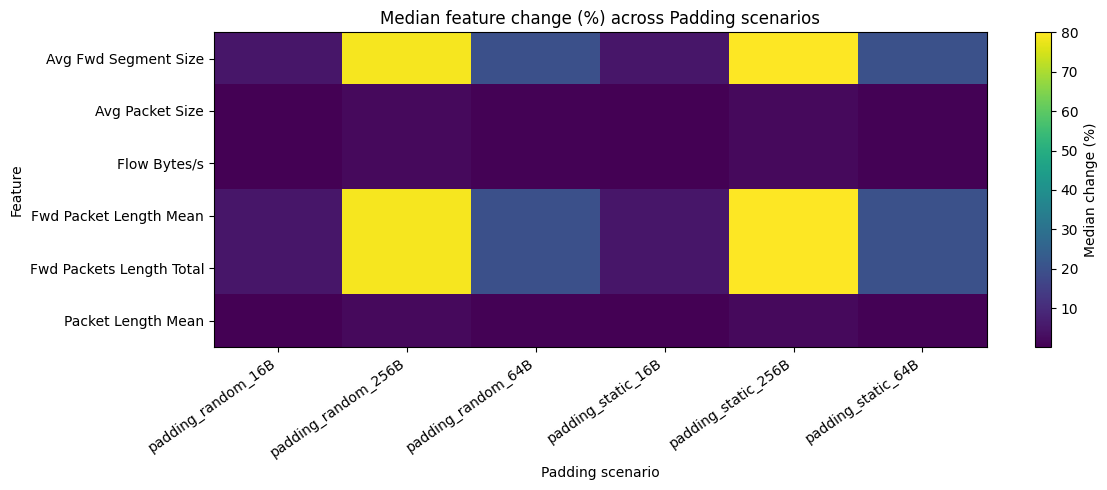

In [ ]:
# 5.2. FEATURE CHANGE HEATMAP

heatmap_delta = delta_df.pivot(
    index="feature",
    columns="scenario",
    values="median_change_pct"
)

fig, ax = plt.subplots(figsize=(12, 5))

im = ax.imshow(heatmap_delta.values, aspect="auto")

ax.set_xticks(np.arange(len(heatmap_delta.columns)))
ax.set_xticklabels(heatmap_delta.columns, rotation=35, ha="right")

ax.set_yticks(np.arange(len(heatmap_delta.index)))
ax.set_yticklabels(heatmap_delta.index)

ax.set_title("Median feature change (%) across Padding scenarios")
ax.set_xlabel("Padding scenario")
ax.set_ylabel("Feature")

plt.colorbar(im, ax=ax, label="Median change (%)")
plt.tight_layout()
plt.show()

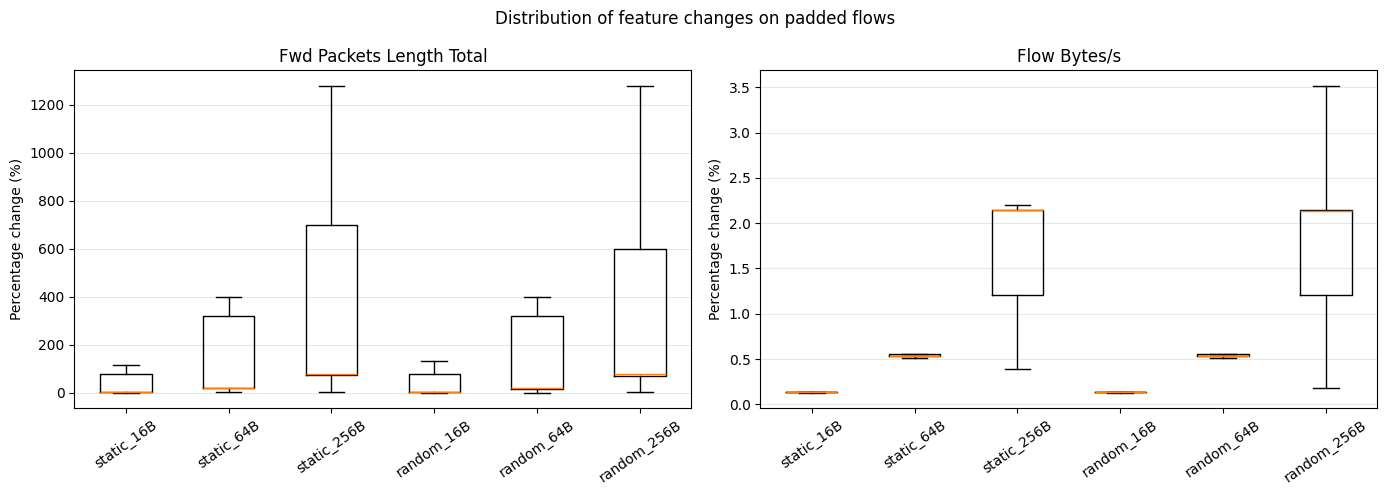

In [ ]:
# 5.3. DISTRIBUTION OF FEATURE CHANGES

features_for_boxplot = [
    "Fwd Packets Length Total",
    "Flow Bytes/s"
]

fig, axes = plt.subplots(
    1, 2, figsize=(14, 5)
)

for ax, feature in zip(axes, features_for_boxplot):
    data = []
    labels = []

    for tag, out in kept.items():
        mask = out["__padding_applied"].to_numpy(dtype=bool)

        if not mask.any():
            continue

        row_ids = out.loc[mask, "__orig_row"].to_numpy()
        old = orig.iloc[row_ids][feature].to_numpy(dtype=float)
        new = out.loc[mask, feature].to_numpy(dtype=float)

        delta_pct = (
            (new - old) / np.maximum(np.abs(old), 1e-9)
        ) * 100

        data.append(delta_pct)
        labels.append(tag.replace("padding_", ""))

    ax.boxplot(data, tick_labels=labels, showfliers=False)
    ax.set_title(feature)
    ax.set_ylabel("Percentage change (%)")
    ax.tick_params(axis="x", rotation=35)
    ax.grid(axis="y", alpha=0.3)

plt.suptitle("Distribution of feature changes on padded flows")
plt.tight_layout()
plt.show()

In [ ]:
# 5.4. PRESERVED FEATURES CHECK

preserved_cols = [
    c for c in PL.PRESERVED_UNIDENTIFIABLE_COLS
    if c in FEATURES
]

preserved_rows = []

for tag, out in kept.items():
    changed = out["__padding_applied"].to_numpy(dtype=bool)

    for col in preserved_cols:
        old = orig[col].to_numpy(dtype=float)
        new = out[col].to_numpy(dtype=float)

        max_diff = np.max(np.abs(new - old)) if len(old) else 0

        preserved_rows.append({
            "scenario": tag,
            "feature": col,
            "max_absolute_difference": max_diff,
            "unchanged": np.allclose(
                new, old, rtol=1e-6, atol=1e-9
            )
        })

preserved_df = pd.DataFrame(preserved_rows)
display(preserved_df)

,scenario,feature,max_absolute_difference,unchanged
0,padding_static_16B,Fwd Packet Length Min,0.0,True
1,padding_static_16B,Fwd Packet Length Max,0.0,True
2,padding_static_16B,Fwd Packet Length Std,0.0,True
3,padding_static_16B,Packet Length Min,0.0,True
4,padding_static_16B,Packet Length Max,0.0,True
5,padding_static_16B,Packet Length Std,0.0,True
6,padding_static_16B,Packet Length Variance,0.0,True
7,padding_static_16B,Subflow Fwd Bytes,0.0,True
8,padding_static_16B,Fwd Avg Bytes/Bulk,0.0,True
9,padding_static_16B,Fwd Avg Bulk Rate,0.0,True


## 6. Đầu ra



| File | Nội dung |
|---|---|
| `test_padding_<mode>_<P>B.parquet` | Flow features chưa scale, nhãn và cờ trạng thái Padding |
| `test_padding_<mode>_<P>B_scaled.npz` | Dữ liệu đã scale bằng scaler của tập train |
| `padding_summary.csv` | Số flow áp dụng được, được Padding, không áp dụng và validation failed |
| `validation_report.csv` | Số vi phạm theo từng quy tắc |
| `manifest.json` | Cấu hình, phạm vi và chính sách cập nhật feature |
